# BÀI THỰC HÀNH 00: KHẢO SÁT VÀ KIỂM TRA DỮ LIỆU RIASEC27
- Mục tiêu: Kiểm tra tính toàn vẹn 4.910 dòng × 33 cột dữ liệu khảo sát và đối chiếu với bản gốc.

In [1]:
from pathlib import Path
import sys, hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from openpyxl.utils import get_column_letter
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'dataLabanAI.xlsx').is_file())
source_path = ROOT/'dataLabanAI.xlsx'
original_path = ROOT/'Data Student_Full.xlsx'
if not original_path.is_file():
    raise FileNotFoundError('Chưa đọc được bản gốc để đối chiếu; dừng trước kết luận nguồn đã xác minh.')
hashes_before = {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [source_path,original_path]}
display(pd.Series(hashes_before,name='SHA-256 trước audit').to_frame())
print('Python:',sys.version)
print('Interpreter:',sys.executable)


                                                      SHA-256 trước audit
dataLabanAI.xlsx        c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48...
Data Student_Full.xlsx  f3a4721d6630a8d7981a522eee691e93d65c8140956bfe...
Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Interpreter: C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe


## Bước 1: Khai báo thư viện và đọc dữ liệu
- Đầu vào: Tệp `dataLabanAI.xlsx` (Python 3.14, pandas, numpy).

In [2]:
excel = pd.ExcelFile(source_path)
expected_sheets = ['THONG_TIN','RIASEC_27','SO_THICH_6','CODEBOOK_33','KIEM_TRA']
display(pd.DataFrame({'Sheet thực tế':excel.sheet_names}))
assert excel.sheet_names == expected_sheets
sheets = {name:pd.read_excel(excel,sheet_name=name) for name in excel.sheet_names}
display(pd.DataFrame([{'Sheet':name,'Số dòng':len(frame),'Số cột':frame.shape[1]} for name,frame in sheets.items()]))
info = sheets['THONG_TIN']
riasec = sheets['RIASEC_27']
preferences = sheets['SO_THICH_6']
codebook = sheets['CODEBOOK_33']
checks_declared = sheets['KIEM_TRA']
question_columns = ['R1','I1','A1','R2','I2','A2','S1','S2','R3','A3','S3','E1','R4','S4','E2','R5','I3','A4','E3','I4','A5','E4','C1','E5','C2','C3','C4']
q5_columns = ['Q5_LikeRe','Q5_LikeIn','Q5_LikeAr','Q5_LikeSo','Q5_LikeEn','Q5_LikeCo']
all_columns = question_columns + q5_columns
assert riasec.shape==(4910,28) and preferences.shape==(4910,7)
assert riasec.columns.tolist()==['SOURCE_ROW']+question_columns
assert preferences.columns.tolist()==['SOURCE_ROW']+q5_columns
assert riasec.SOURCE_ROW.is_unique and preferences.SOURCE_ROW.is_unique
assert riasec.SOURCE_ROW.equals(preferences.SOURCE_ROW)
assert pd.api.types.is_integer_dtype(riasec.SOURCE_ROW)
assert codebook.MA_COT.is_unique and codebook.MA_COT.tolist()==all_columns
X27 = riasec[question_columns].copy()
Q5 = preferences[q5_columns].copy()
assert 'SOURCE_ROW' not in X27.columns
assert list(X27.columns)==question_columns
print('PASS: 4.910 dòng, đúng thứ tự 27+6 câu; SOURCE_ROW duy nhất và khớp.')


PASS: 4.910 dòng, đúng thứ tự 27+6 câu; SOURCE_ROW duy nhất và khớp.


  Sheet thực tế
0     THONG_TIN
1     RIASEC_27
2    SO_THICH_6
3   CODEBOOK_33
4      KIEM_TRA

         Sheet  Số dòng  Số cột
0    THONG_TIN       23       2
1    RIASEC_27     4910      28
2   SO_THICH_6     4910       7
3  CODEBOOK_33       33       5
4     KIEM_TRA       33       6

## Bước 2: Đối chiếu toàn vẹn với dữ liệu gốc
- Đầu vào: `dataLabanAI.xlsx` và `survey_original.xlsx`.
- Đầu ra: Xác nhận khớp 100% (162.030 ô dữ liệu, mã SHA-256 trùng khớp).

In [3]:
original_excel = pd.ExcelFile(original_path)
assert original_excel.sheet_names==['Data','Code book']
original_headers = pd.read_excel(original_excel,sheet_name='Data',nrows=0).columns.tolist()
original_survey = pd.read_excel(original_excel,sheet_name='Data',usecols=all_columns)
original_codebook = pd.read_excel(original_excel,sheet_name='Code book')
print('Bản gốc: số dòng Data =',len(original_survey),'; số cột Data =',len(original_headers))
print('Code book gốc:',original_codebook.shape)
assert len(original_headers)==81 and len(original_survey)==4910
assert original_codebook.Code.is_unique
original_cb = original_codebook.set_index('Code')
assert set(all_columns).issubset(original_cb.index)
assert original_survey.columns.tolist()==all_columns
assert riasec.SOURCE_ROW.tolist()==list(range(2,len(original_survey)+2))
source_positions = riasec.SOURCE_ROW.to_numpy()-2
combined = pd.concat([X27,Q5],axis=1)
comparison_rows = []
for position,col in enumerate(all_columns):
    item = codebook.set_index('MA_COT').loc[col]
    original_values = original_survey.iloc[source_positions][col].to_numpy()
    mismatch = ~((combined[col].to_numpy()==original_values) |
                 (pd.isna(combined[col].to_numpy()) & pd.isna(original_values)))
    comparison_rows.append({'Mã':col,'Thứ tự khớp':original_headers[37+position]==col,
        'Số ô khác':int(mismatch.sum()),
        'Nội dung khớp':item.NOI_DUNG_CODEBOOK==original_cb.loc[col,'Label'],
        'Thang đo khớp':item.THANG_DIEM_GOC==original_cb.loc[col,'Value'],
        'Cột Excel khớp':item.COT_TRONG_FILE_GOC==get_column_letter(original_headers.index(col)+1)})
comparison = pd.DataFrame(comparison_rows)
display(comparison)
flags = ['Thứ tự khớp','Nội dung khớp','Thang đo khớp','Cột Excel khớp']
if comparison['Số ô khác'].sum() or not comparison[flags].all().all():
    raise RuntimeError('Có sai khác: dừng trước các kết luận phụ thuộc dữ liệu chưa xác minh.')
claimed_hash = info.loc[info.iloc[:,0].eq('SHA-256 tệp nhận')].iloc[0,1]
assert hashes_before[original_path.name]==claimed_hash
print('PASS: 162.030 ô khảo sát, 33 nội dung/thang đo/thứ tự/cột nguồn khớp; hash bản gốc khớp ghi chú.')
# Không dùng các biến ngoài 33 câu cho phân tích phản hồi.
del original_survey


Bản gốc: số dòng Data = 4910 ; số cột Data = 81
Code book gốc: (81, 3)
PASS: 162.030 ô khảo sát, 33 nội dung/thang đo/thứ tự/cột nguồn khớp; hash bản gốc khớp ghi chú.


           Mã  Thứ tự khớp  Số ô khác  Nội dung khớp  Thang đo khớp  Cột Excel khớp
0          R1         True          0           True           True            True
1          I1         True          0           True           True            True
2          A1         True          0           True           True            True
3          R2         True          0           True           True            True
4          I2         True          0           True           True            True
5          A2         True          0           True           True            True
6          S1         True          0           True           True            True
7          S2         True          0           True           True            True
8          R3         True          0           True           True            True
9          A3         True          0           True           True            True
10         S3         True          0           True           True         

In [4]:
groups = {key:[col for col in question_columns if col.startswith(key)] for key in ['R','I','A','S','E','C']}
assert {key:len(cols) for key,cols in groups.items()}=={'R':5,'I':4,'A':5,'S':4,'E':5,'C':4}
group_table = pd.DataFrame([{'Nhóm':key,'Số câu':len(cols),'Các câu':', '.join(cols)} for key,cols in groups.items()])
display(group_table)
print('27 câu — nguyên văn codebook gốc, theo thứ tự đầu vào:')
display(original_cb.loc[question_columns,['Label','Value']])
print('Sáu biến Q5 — nguyên văn codebook gốc:')
display(original_cb.loc[q5_columns,['Label','Value']])
print('Các biến ngoài 33 câu — chỉ xem định nghĩa để kiểm tra có nhãn ngành hay không:')
non_survey_metadata = original_codebook.loc[~original_codebook.Code.isin(all_columns),['Code','Label']]
display(non_survey_metadata)


27 câu — nguyên văn codebook gốc, theo thứ tự đầu vào:
Sáu biến Q5 — nguyên văn codebook gốc:
Các biến ngoài 33 câu — chỉ xem định nghĩa để kiểm tra có nhãn ngành hay không:


  Nhóm  Số câu             Các câu
0    R       5  R1, R2, R3, R4, R5
1    I       4      I1, I2, I3, I4
2    A       5  A1, A2, A3, A4, A5
3    S       4      S1, S2, S3, S4
4    E       5  E1, E2, E3, E4, E5
5    C       4      C1, C2, C3, C4

                                                                                                                                                                          Label                                                                       Value
Code                                                                                                                                                                                                                                                       
R1                        Which of the following activities did you enjoy doing when you were in lower secondary school? [I like assembling and repairing electronic equipment]  1. Strongly Disagree; 2. Disagree; 3. Neutral; 4. Agree; 5. Strongly Agree
I1                   Which of the following activities did you enjoy doing when you were in lower secondary school? [I like solving complex math problems and proving theorems]  1. Strongly Disagree; 2. Disagree; 3. Neutral; 4. Agree; 5. Strongl

                                                                                                                                                                     Label                                                                   Value
Code                                                                                                                                                                                                                                              
Q5_LikeRe  Which of the following career groups do you prefer? [Realistic / Technical & Technology (such as architecture, construction, mechanics, electronics, geology…)]  1: Strongly dislike; 2: Dislike; 3: Neutral; 4: Like; 5: Strongly like
Q5_LikeIn                  Which of the following career groups do you prefer? [Investigative / Research (such as mathematics, psychology, sociology, natural sciences,…)]  1: Strongly dislike; 2: Dislike; 3: Neutral; 4: Like; 5: Strongly like
Q5_LikeAr                 Wh

                Code                                                                                                                                                                                               Label
0               IDST                                                                                                                                                                                          ID Student
1    P1Q2_TypeSchool                                                                                                                                                                                          TypeSchool
2     P1Q3_TypeClass                                                                                                                                                                                           TypeClass
3           Province                                                                                                                

## Bước 3: Kiểm tra Codebook và Thang đo Likert [1, 5]
- Đầu vào: 27 câu hỏi RIASEC rút gọn và 6 biến mục tiêu Q5.
- Yêu cầu: Miền giá trị số nguyên từ 1 đến 5, không có giá trị khuyết thiếu.

Tỷ lệ từng mức cho đủ 33 câu (%):
Số câu variance=0: 0


           Số dòng  Thiếu  Ngoài miền hoặc không phải số nguyên  Min  Max  Số mức    Mean  Median  SD (ddof=1)  Variance (ddof=0)
Mã                                                                                                                               
R1            4910      0                                     0    1    5       5  2.5352     3.0       1.0994             1.2084
I1            4910      0                                     0    1    5       5  2.6776     3.0       1.1142             1.2413
A1            4910      0                                     0    1    5       5  2.7868     3.0       1.1240             1.2631
R2            4910      0                                     0    1    5       5  2.6204     3.0       1.0541             1.1109
I2            4910      0                                     0    1    5       5  2.5910     3.0       1.0797             1.1655
A2            4910      0                                     0    1    5       5  2.5796 

           Mức 1  Mức 2  Mức 3  Mức 4  Mức 5
R1         19.59  30.31  32.46  12.26   5.38
I1         17.49  24.99  35.68  15.93   5.91
A1         14.26  25.68  34.83  17.60   7.64
R2         16.15  29.23  35.11  15.46   4.05
I2         16.76  31.26  33.63  12.81   5.54
A2         16.90  32.12  32.61  12.85   5.52
S1         15.44  27.78  33.12  16.05   7.62
S2         14.32  25.82  35.64  16.60   7.62
R3         20.49  33.75  28.68  11.75   5.34
A3         13.95  21.28  31.55  20.71  12.51
S3         17.68  28.53  33.05  13.73   7.01
E1         16.92  29.74  32.04  15.44   5.87
R4         18.66  34.52  32.18  10.90   3.75
S4         10.12  15.01  34.95  27.13  12.79
E2         12.85  22.38  33.20  21.49  10.08
R5         24.36  37.76  27.03   7.92   2.93
I3         17.09  26.54  31.51  16.84   8.02
A4         19.78  28.37  30.33  14.03   7.49
E3         12.28  20.98  36.09  19.92  10.73
I4         14.83  27.98  32.79  16.44   7.96
A5         19.94  33.83  30.77  10.41   5.05
E4        

   RIASEC27    Q5
1     22409  6313
2     38022  6337
3     43821  8280
4     19739  4692
5      8579  3838

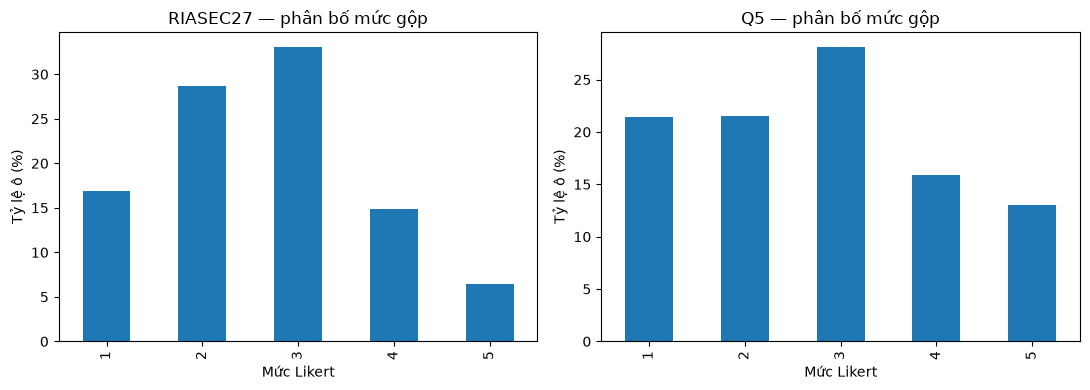

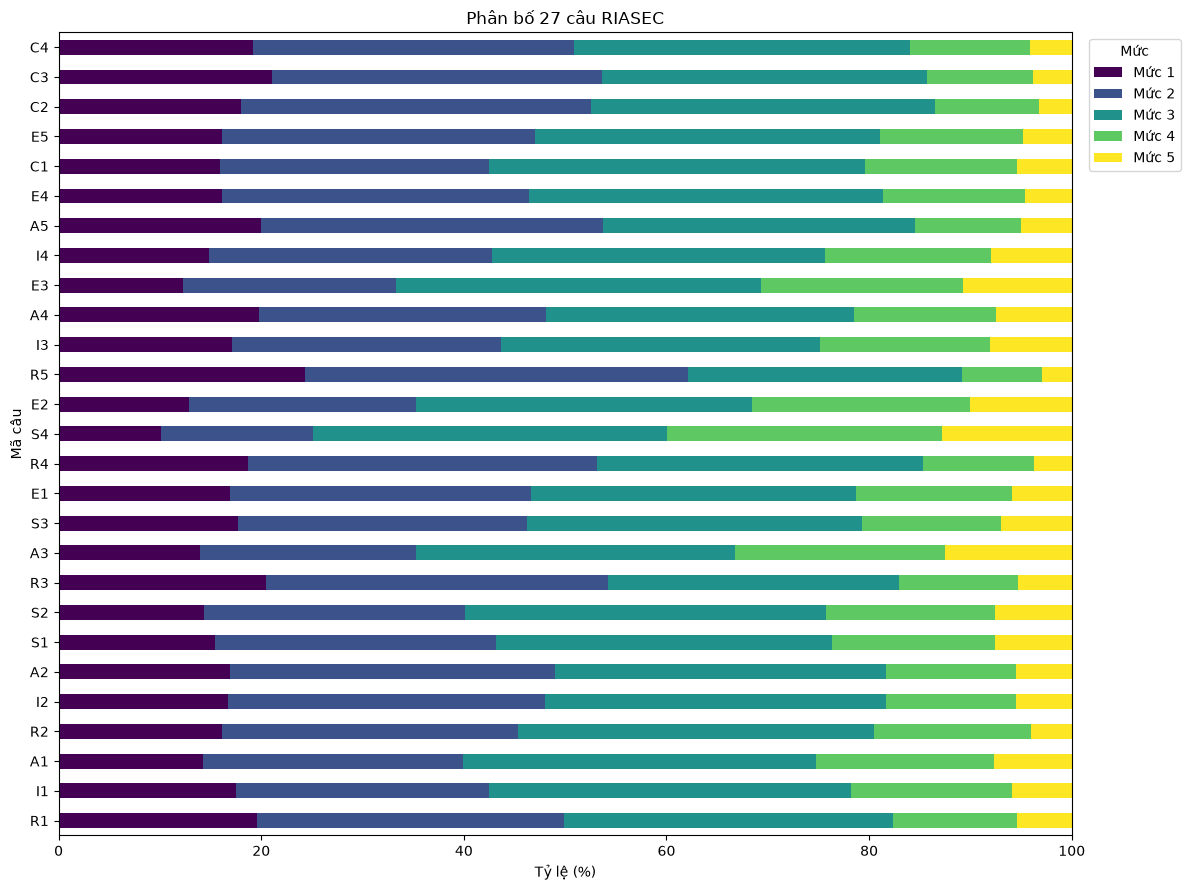

In [5]:
quality_rows = []
for col in all_columns:
    values = combined[col]
    numeric = pd.to_numeric(values,errors='coerce')
    quality_rows.append({'Mã':col,'Số dòng':len(values),'Thiếu':int(values.isna().sum()),
        'Ngoài miền hoặc không phải số nguyên':int((values.notna() & (~numeric.isin([1,2,3,4,5]))).sum()),
        'Min':numeric.min(),'Max':numeric.max(),'Số mức':numeric.nunique(),
        'Mean':numeric.mean(),'Median':numeric.median(),'SD (ddof=1)':numeric.std(ddof=1),
        'Variance (ddof=0)':numeric.var(ddof=0)})
quality = pd.DataFrame(quality_rows).set_index('Mã')
display(quality.round(4))
assert quality['Thiếu'].sum()==0
assert quality['Ngoài miền hoặc không phải số nguyên'].sum()==0
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in combined.dtypes)
# Đối chiếu báo cáo kiểm tra có sẵn, không chỉ chấp nhận số liệu ghi sẵn.
assert checks_declared.BIEN.is_unique and set(checks_declared.BIEN)==set(all_columns)
declared = checks_declared.set_index('BIEN').loc[all_columns]
assert np.array_equal(declared['SO_MAU'],quality['Số dòng'])
assert np.array_equal(declared['GIA_TRI_THIEU'],quality['Thiếu'])
assert np.array_equal(declared['NGOAI_MIỀN_1_5'],quality['Ngoài miền hoặc không phải số nguyên'])
assert np.array_equal(declared['GIA_TRI_HOP_LE'],quality['Số dòng']-quality['Thiếu']-quality['Ngoài miền hoặc không phải số nguyên'])
level_counts = pd.DataFrame({col:combined[col].value_counts().reindex(range(1,6),fill_value=0) for col in all_columns}).T
level_counts.columns = [f'Mức {i}' for i in range(1,6)]
level_rates = level_counts/len(combined)*100
print('Tỷ lệ từng mức cho đủ 33 câu (%):')
display(level_rates.round(2))
aggregate = pd.DataFrame({'RIASEC27':X27.stack().value_counts().reindex(range(1,6),fill_value=0),
                          'Q5':Q5.stack().value_counts().reindex(range(1,6),fill_value=0)})
display(aggregate)
fig,axes = plt.subplots(1,2,figsize=(11,4))
for ax,name in zip(axes,['RIASEC27','Q5']):
    (aggregate[name]/aggregate[name].sum()*100).plot.bar(ax=ax)
    ax.set(title=name+' — phân bố mức gộp',xlabel='Mức Likert',ylabel='Tỷ lệ ô (%)')
plt.tight_layout()
plt.show()
fig,ax = plt.subplots(figsize=(12,9))
level_rates.loc[question_columns].plot.barh(stacked=True,ax=ax,colormap='viridis')
ax.set(title='Phân bố 27 câu RIASEC',xlabel='Tỷ lệ (%)',ylabel='Mã câu',xlim=(0,100))
ax.legend(title='Mức',bbox_to_anchor=(1.01,1))
plt.tight_layout()
plt.show()
print('Số câu variance=0:',int(quality['Variance (ddof=0)'].eq(0).sum()))

In [6]:
group_ids = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X27),sort=False)[0],index=X27.index)
vector_sizes = group_ids.value_counts()
duplicate_ids = vector_sizes.index[vector_sizes.gt(1)]
straightline = X27.nunique(axis=1).eq(1)
q5_distinct = Q5.groupby(group_ids).nunique()
conflict_ids = q5_distinct.index[q5_distinct.gt(1).any(axis=1)]
tied_counts = Q5.eq(Q5.max(axis=1),axis=0).sum(axis=1)
summary = pd.Series({
    'Tổng số dòng':len(X27),'Vector X27 phân biệt':len(vector_sizes),
    'Dòng trùng thêm X27':int(X27.duplicated().sum()),
    'Nhóm X27 trùng':len(duplicate_ids),'Dòng thuộc nhóm X27 trùng':int(vector_sizes.loc[duplicate_ids].sum()),
    'Kích thước nhóm trùng lớn nhất':int(vector_sizes.max()),
    'Dòng cùng một mức cho cả 27 câu':int(straightline.sum()),
    'Nhóm cùng X27 nhưng Q5 khác':len(conflict_ids),
    'Dòng thuộc nhóm cùng X27 nhưng Q5 khác':int(group_ids.isin(conflict_ids).sum()),
    'Dòng trùng thêm đủ 33 câu':int(combined.duplicated().sum()),
    'Dòng đồng hạng tối đa ở Q5':int(tied_counts.gt(1).sum())},name='Kết quả')
display(summary.to_frame())
print('Phân bố số lần lặp theo kích thước nhóm, không in vector:')
display(vector_sizes.value_counts().sort_index().rename_axis('Số dòng/nhóm').rename('Số nhóm').to_frame())
print('Dòng chọn cùng mức, phân theo mức:')
display(X27.loc[straightline,question_columns[0]].value_counts().sort_index().rename('Số dòng').to_frame())
print('Số biến Q5 cùng đạt mức cao nhất trong mỗi dòng:')
display(tied_counts.value_counts().sort_index().rename_axis('Số biến đồng hạng').rename('Số dòng').to_frame())
assert summary['Vector X27 phân biệt']+summary['Dòng trùng thêm X27']==len(X27)


Phân bố số lần lặp theo kích thước nhóm, không in vector:
Dòng chọn cùng mức, phân theo mức:
Số biến Q5 cùng đạt mức cao nhất trong mỗi dòng:


                                        Kết quả
Tổng số dòng                               4910
Vector X27 phân biệt                       4460
Dòng trùng thêm X27                         450
Nhóm X27 trùng                               57
Dòng thuộc nhóm X27 trùng                   507
Kích thước nhóm trùng lớn nhất              188
Dòng cùng một mức cho cả 27 câu             347
Nhóm cùng X27 nhưng Q5 khác                  54
Dòng thuộc nhóm cùng X27 nhưng Q5 khác      501
Dòng trùng thêm đủ 33 câu                   239
Dòng đồng hạng tối đa ở Q5                 2673

              Số nhóm
Số dòng/nhóm         
1                4403
2                  30
3                  11
4                   2
5                   5
6                   1
7                   2
14                  1
24                  1
38                  1
41                  1
56                  1
188                 1

    Số dòng
R1         
1        41
2        38
3       188
4        56
5        24

                   Số dòng
Số biến đồng hạng         
1                     2237
2                     1058
3                      532
4                      228
5                      128
6                      727

## Bước 4: Đánh giá chất lượng dữ liệu và vector phản hồi
- Phân tích: Tính đa dạng vector trả lời và độ phân tán điểm số các nhóm RIASEC.

Q5 là sáu mức được hỏi riêng, không phải các mean ở bảng trên:


   Số câu    mean     std  min   25%   50%   75%  max
R       5  2.4743  0.8400  1.0  2.00  2.40  3.00  5.0
I       4  2.6844  0.8339  1.0  2.00  2.75  3.25  5.0
A       5  2.6822  0.8385  1.0  2.00  2.60  3.20  5.0
S       4  2.8283  0.8359  1.0  2.25  3.00  3.25  5.0
E       5  2.7482  0.8449  1.0  2.20  2.80  3.20  5.0
C       4  2.5173  0.8734  1.0  2.00  2.50  3.00  5.0

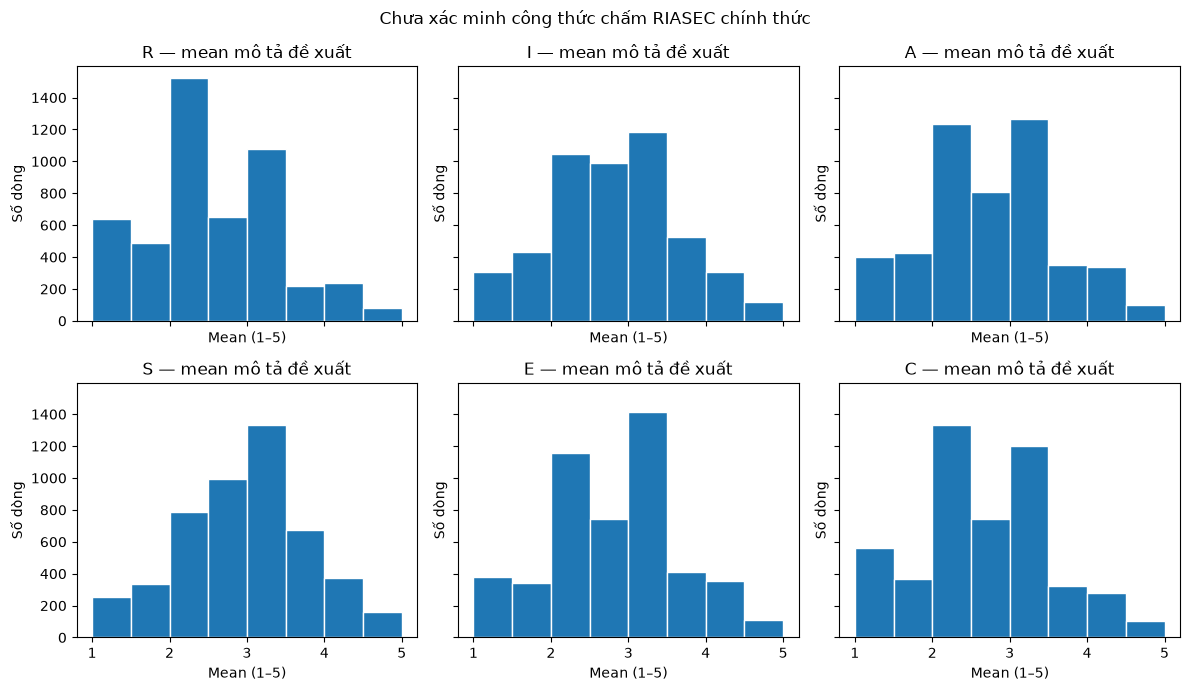

            count    mean     std  min  50%  max
Q5_LikeRe  4910.0  2.4939  1.2525  1.0  2.0  5.0
Q5_LikeIn  4910.0  2.7701  1.3138  1.0  3.0  5.0
Q5_LikeAr  4910.0  2.9672  1.3573  1.0  3.0  5.0
Q5_LikeSo  4910.0  2.8548  1.2808  1.0  3.0  5.0
Q5_LikeEn  4910.0  2.8652  1.2911  1.0  3.0  5.0
Q5_LikeCo  4910.0  2.7057  1.2796  1.0  3.0  5.0

In [7]:
proposed_means = pd.DataFrame({key:X27[cols].mean(axis=1) for key,cols in groups.items()})
assert proposed_means.ge(1).all().all() and proposed_means.le(5).all().all()
group_stats = proposed_means.describe().T[['mean','std','min','25%','50%','75%','max']]
group_stats.insert(0,'Số câu',[len(groups[key]) for key in group_stats.index])
display(group_stats.round(4))
fig,axes = plt.subplots(2,3,figsize=(12,7),sharex=True,sharey=True)
for ax,key in zip(axes.flat,groups):
    ax.hist(proposed_means[key],bins=np.linspace(1,5,9),edgecolor='white')
    ax.set(title=key+' — mean mô tả đề xuất',xlabel='Mean (1–5)',ylabel='Số dòng')
fig.suptitle('Chưa xác minh công thức chấm RIASEC chính thức')
plt.tight_layout()
plt.show()
print('Q5 là sáu mức được hỏi riêng, không phải các mean ở bảng trên:')
display(Q5.describe().T[['count','mean','std','min','50%','max']].round(4))

## Bước 5: Định hướng bài toán nghiên cứu (Hướng B)
- Mục tiêu: Dự đoán 6 nhóm sở thích nghề nghiệp RIASEC từ 27 câu trắc nghiệm.

In [8]:
hashes_after = {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [source_path,original_path]}
assert hashes_before==hashes_after
assert X27.equals(riasec[question_columns]) and Q5.equals(preferences[q5_columns])
assert len(X27)==4910 and len(Q5)==4910
assert 'SOURCE_ROW' not in X27.columns and list(X27.columns)==question_columns
display(pd.DataFrame({'SHA-256 trước':hashes_before,'SHA-256 sau':hashes_after}))
print('PASS: hai workbook không đổi, không xóa/sửa câu trả lời, không chia tập hoặc huấn luyện.')
print('Dừng sau Notebook 00. Chưa tạo Notebook 01.')

PASS: hai workbook không đổi, không xóa/sửa câu trả lời, không chia tập hoặc huấn luyện.
Dừng sau Notebook 00. Chưa tạo Notebook 01.


                                                                           SHA-256 trước                                                       SHA-256 sau
dataLabanAI.xlsx        c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8  c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8
Data Student_Full.xlsx  f3a4721d6630a8d7981a522eee691e93d65c8140956bfe24576255b6250d0cdb  f3a4721d6630a8d7981a522eee691e93d65c8140956bfe24576255b6250d0cdb

## Bước 6: Kiểm tra tính bất biến và Tổng kết
- Xác nhận: Mã băm SHA-256 không đổi, 4.910 mẫu sẵn sàng cho bài thực hành tiếp theo.